# 05 · 把方法放回同一辆车：比较、失败与下一步研究

这篇把整条路线收束到可以复现的研究实验：先让 PID、LQR、MPC 在同样条件下停靠，再分别加入外力、质量失配、位置测量噪声。

**学习成果：** 写出不混淆假设的比较协议；检查约束与求解状态；连接 Kalman 与 MPC；选择值得继续研究的方向。

本篇完整包含模型和控制器，不依赖前几篇的内核变量。第一次阅读可以直接看实验协议与结果，想追溯公式再回到对应篇章。


[00 学习地图与小车建模](00_学习地图与小车建模.ipynb) · [01 经典控制与PID](01_经典控制与PID.ipynb) · [02 状态空间与LQR](02_状态空间与LQR.ipynb) · [03 观测器与Kalman滤波](03_观测器与Kalman滤波.ipynb) · [04 从有限时域优化到MPC](04_从有限时域优化到MPC.ipynb) · [05 综合实验与进阶路线](05_综合实验与进阶路线.ipynb)

每篇可独立运行；本篇内按顺序执行。图中英文标签对应正文中文术语，避免依赖本机中文字体。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, linalg

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 3.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
DT = 0.1
MASS, DRAG = 1.0, 0.4
C = np.array([[1.0, 0.0]])

def model(mass=MASS, drag=DRAG):
    Ac = np.array([[0.0, 1.0], [0.0, -drag / mass]])
    Bc = np.array([[0.0], [1.0 / mass]])
    A, B, _, _, _ = signal.cont2discrete((Ac, Bc, C, np.zeros((1, 1))), DT)
    return A, B

A, B = model()
b = B[:, 0]
REF = np.array([1.0, 0.0])

def rollout(policy, steps=120, x0=(0.0, 0.0), disturbance=None, plant=None):
    Ap, Bp = (A, B) if plant is None else plant
    xs, us = [np.array(x0, dtype=float)], []
    for k in range(steps):
        u = float(policy(xs[-1].copy(), k))
        d = 0.0 if disturbance is None else float(disturbance(k))
        xs.append(Ap @ xs[-1] + Bp[:, 0] * (u + d))
        us.append(u)
    return np.asarray(xs), np.asarray(us)

def plot_runs(runs, title, wall=None):
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
    for label, (xs, us) in runs.items():
        axes[0].plot(np.arange(len(xs))*DT, xs[:, 0], label=label)
        axes[1].plot(np.arange(len(xs))*DT, xs[:, 1], label=label)
        axes[2].step(np.arange(len(us))*DT, us, where="post", label=label)
    axes[0].axhline(REF[0], color="black", ls=":", label="target")
    if wall is not None:
        axes[0].axhline(wall, color="firebrick", ls="--", label="position limit")
    for ax, label in zip(axes, ["position [m]", "velocity [m/s]", "force [N]"]):
        ax.set_ylabel(label)
    axes[0].legend(ncol=3, fontsize=8)
    axes[-1].set_xlabel("time [s]")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


In [2]:
Q = np.diag([20.0, 2.0])
R = np.array([[0.5]])
P = linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.solve(R + B.T @ P @ B, B.T @ P @ A)


In [3]:
import cvxpy as cp
from time import perf_counter

def make_mpc(horizon=30, constrained=True, soft=False, terminal=None,
             wall=1.05, vmax=0.8, umax=1.0):
    terminal = P if terminal is None else terminal
    X = cp.Variable((2, horizon+1))
    U = cp.Variable(horizon)
    initial = cp.Parameter(2)
    constraints = [X[:, 0] == initial]
    slack = cp.Variable((2, horizon), nonneg=True) if soft else None
    objective = 0
    for i in range(horizon):
        objective += cp.quad_form(X[:, i]-REF, Q) + R.item()*cp.square(U[i])
        constraints += [X[:, i+1] == A@X[:, i]+b*U[i]]
        if constrained:
            constraints += [cp.abs(U[i]) <= umax]
            sp = slack[0, i] if soft else 0.0
            sv = slack[1, i] if soft else 0.0
            constraints += [X[0, i+1] <= wall+sp,
                            cp.abs(X[1, i+1]) <= vmax+sv]
    objective += cp.quad_form(X[:, -1]-REF, terminal)
    if soft:
        objective += 1e4*cp.sum(slack) + 1e3*cp.sum_squares(slack)
    problem = cp.Problem(cp.Minimize(objective), constraints)
    assert problem.is_dcp() and problem.is_dpp()

    def solve(state):
        initial.value = np.asarray(state, dtype=float)
        start = perf_counter()
        try:
            problem.solve(solver=cp.OSQP, warm_start=True,
                          eps_abs=1e-7, eps_rel=1e-7, max_iter=100000,
                          polishing=True)
        except cp.error.SolverError as exc:
            raise RuntimeError("MPC solver failure; no action was applied") from exc
        elapsed = perf_counter()-start
        if problem.status != cp.OPTIMAL:
            raise RuntimeError(f"MPC status={problem.status}; no action was applied")
        violation = max(float(np.max(c.violation())) for c in constraints)
        if violation > 5e-5:
            raise RuntimeError(f"MPC residual too large: {violation}")
        raw = float(U.value[0])
        # Remove only solver-level bound roundoff; this is not clipped LQR.
        action = float(np.clip(raw, -umax, umax)) if constrained else raw
        return {"u": action, "X": X.value.copy(), "U": U.value.copy(),
                "cost": float(problem.value), "wall_time": elapsed,
                "solver_time": problem.solver_stats.solve_time,
                "violation": violation,
                "slack": None if slack is None else slack.value.copy()}
    return solve


## 1. 先约定如何比较

统一任务：从 $x_0=[0,0]^T$ 出发，在 12 秒内停到 $x_r=[1,0]^T$；实际执行器均限幅 ±1 N；设计质量 1 kg、阻力 0.4；采样周期 0.1 秒。

第一组比较均使用**真实完整状态**，排除估计误差。PID 用固定增益与抗积分饱和，LQR 使用前文 Q/R 后限幅，MPC 使用相同 Q/R 及预测约束。PID 和 LQR 不通过人为减小目标或额外轨迹规划来间接满足速度限制；这是对这三个具体设计的比较，不是算法家族的全面排名。

### 指标约定

- **停稳时间：** 第一次进入且在记录剩余时间始终满足 $|p-1|\le0.02\,m$、$|v|\le0.02\,m/s$ 的时刻，至少还要有 2 秒验证窗口；未满足记 `nan`。
- **超调：** $\max(0,\max p_k-1)$；报告末尾 2 秒平均位置误差。
- **控制努力：** $T_s\sum u_k^2$，不是实际能耗。
- **评价代价：** 共同 Q/R 下的 120 步阶段代价总和，不含终端项，不等于各自内部优化的目标值。
- **违反量：** 分别报告 $|u|-1$、$|v|-0.8$、$p-1.05$ 的最大正部；首先只检查采样点。

发生求解失败就停止该条轨迹，保留已执行部分并标记失败；不把短轨迹的低代价当成表现更好。


In [4]:
def pid_policy():
    z = 0.0
    def policy(x, k):
        nonlocal z
        error = REF[0]-x[0]
        raw = 4.0*error + 1.5*z - 3.6*x[1]
        u = float(np.clip(raw, -1, 1))
        if (raw-u)*error <= 0:
            z += DT*error
        return u
    return policy

def controllers():
    solver = make_mpc()
    return {"PID-AW": pid_policy(),
            "LQR-clip": lambda x, k: np.clip(-(K@(x-REF)).item(), -1, 1),
            "MPC": lambda x, k: solver(x)["u"]}

def run_checked(policy, plant=None, disturbance=None, steps=120):
    Ap, Bp = (A, B) if plant is None else plant
    xs, us, times = [np.zeros(2)], [], []
    failure = None
    for k in range(steps):
        start = perf_counter()
        try:
            u = float(policy(xs[-1].copy(), k))
        except RuntimeError as exc:
            failure = f"step {k}: {exc}"
            break
        times.append(perf_counter()-start)
        d = 0.0 if disturbance is None else disturbance(k)
        xs.append(Ap@xs[-1]+Bp[:, 0]*(u+d))
        us.append(u)
    return {"xs": np.asarray(xs), "us": np.asarray(us),
            "times": np.asarray(times), "failure": failure,
            "complete": len(us) == steps}

def metrics(run):
    xs, us = run["xs"], run["us"]
    e = xs-REF
    inside = (np.abs(e[:, 0]) <= 0.02) & (np.abs(xs[:, 1]) <= 0.02)
    stays_inside = np.logical_and.accumulate(inside[::-1])[::-1]
    candidates = np.flatnonzero(stays_inside & (np.arange(len(xs)) <= len(xs)-21))
    settle = candidates[0]*DT if len(candidates) and run["complete"] else np.nan
    stage = np.einsum("ni,ij,nj->n", e[:-1], Q, e[:-1])+R.item()*us**2
    return {"settle_s": settle, "overshoot_m": max(0, xs[:,0].max()-1),
            "tail_error_m": float(np.mean(1-xs[-20:,0])) if run["complete"] else np.nan,
            "effort": DT*float(np.sum(us**2)) if run["complete"] else np.nan,
            "stage_cost": float(stage.sum()) if run["complete"] else np.nan,
            "u_violation": max(0, np.max(np.abs(us), initial=0)-1),
            "v_violation": max(0, np.abs(xs[:,1]).max()-0.8),
            "p_violation": max(0, xs[:,0].max()-1.05)}

def show_table(runs):
    headers = ["settle_s", "overshoot_m", "tail_error_m", "effort",
               "stage_cost", "u_violation", "v_violation", "p_violation"]
    print(f"{'controller':<12}" + " ".join(f"{h:>13}" for h in headers))
    for name, run in runs.items():
        row = metrics(run)
        print(f"{name:<12}" + " ".join(f"{row[h]:13.5f}" for h in headers))
        if run["failure"]:
            print("  STOPPED:", run["failure"])

def as_curves(runs):
    return {name: (run["xs"], run["us"]) for name, run in runs.items()}


## 2. 名义模型：先把基础行为核对好

看结果时先检查三件事：输入是否一致地限幅；MPC 的采样速度与位置约束是否满足；若 PID 用力更少或响应更慢，是否来自它采用了不同的设计偏好。

后面“模型失配”的设计参数保持不变，不重新调参来掩盖失败。


controller       settle_s   overshoot_m  tail_error_m        effort    stage_cost   u_violation   v_violation   p_violation
PID-AW            7.70000       0.15805       0.00123       0.89993     205.69221       0.00000       0.00000       0.10805
LQR-clip          2.60000       0.00939       0.00000       1.27647     191.68339       0.00000       0.01232       0.00000
MPC               2.60000       0.00928       0.00000       1.25072     191.69483       0.00000       0.00000       0.00000


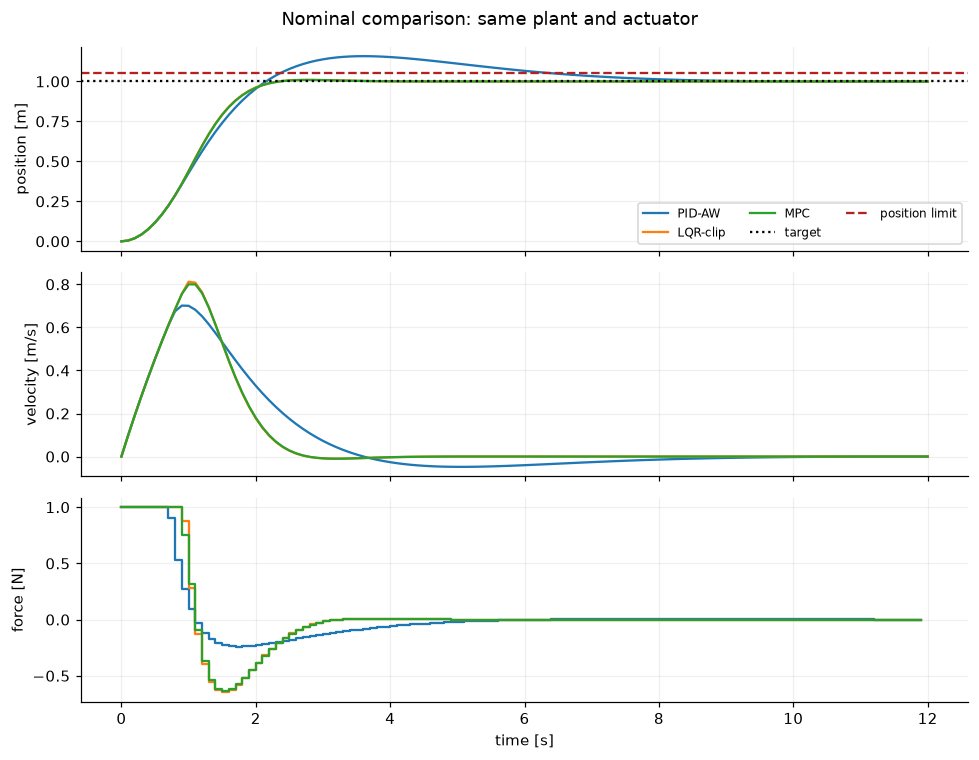

PID-AW: first=0.04 ms, warm median=0.004 ms, max=0.750 ms
LQR-clip: first=0.01 ms, warm median=0.004 ms, max=0.032 ms
MPC: first=105.44 ms, warm median=4.829 ms, max=24.162 ms


In [5]:
nominal = {name: run_checked(policy) for name, policy in controllers().items()}
show_table(nominal)
plot_runs(as_curves(nominal), "Nominal comparison: same plant and actuator", wall=1.05)
assert all(run["complete"] for run in nominal.values())
mpc_metrics = metrics(nominal["MPC"])
assert mpc_metrics["u_violation"] < 1e-8
assert mpc_metrics["v_violation"] < 5e-5
assert mpc_metrics["p_violation"] < 5e-5
for name, run in nominal.items():
    warm = run["times"][1:]
    print(f"{name}: first={run['times'][0]*1000:.2f} ms, "
          f"warm median={np.median(warm)*1000:.3f} ms, max={np.max(warm)*1000:.3f} ms")


计时包含 Python 调用开销；MPC 的首次调用还包含建模编译与求解器初始化。这里只是本机运行观测，不是硬实时最坏耗时证明。部署要另外评估超时、系统调度、内存与故障路径。

## 3. 采样点满足，采样间就一定满足吗？

控制输入在采样间隔内恒定。用连续模型的解析解在每段内取 21 个点，检查是否存在采样间位置峰值。阻力和输入固定时，速度可能在段中变号，位置最大值也可能出现在两次采样之间。

密集采样是附加检查，仍不是连续时间形式证明；严格验证可以求每段 $v(t)=0$ 的候选极值并检查端点，或在设计中加入采样间约束与保守收紧。


In [6]:
def dense_positions(run, mass=MASS, drag=DRAG, disturbance=None):
    tau = np.linspace(0, DT, 21)
    alpha = drag/mass
    decay = np.exp(-alpha*tau)
    drift = (1-decay)/alpha
    values = []
    for k, u in enumerate(run["us"]):
        p, v = run["xs"][k]
        d = 0.0 if disturbance is None else disturbance(k)
        values.append(p+v*drift+(u+d)/drag*(tau-drift))
    return np.asarray(values)

for name, run in nominal.items():
    dense = dense_positions(run)
    assert np.allclose(dense[:, -1], run["xs"][1:, 0])
    print(f"{name}: sampled max={run['xs'][:,0].max():.6f}, "
          f"dense max={dense.max():.6f} m")


PID-AW: sampled max=1.158053, dense max=1.158054 m
LQR-clip: sampled max=1.009391, dense max=1.009415 m
MPC: sampled max=1.009282, dense max=1.009294 m


## 4. 先只加外力，再单独改变质量

实验 A：4 秒后加入恒定向前外力 0.25 N，控制器不知道它。实验 B：真实质量变为 1.6 kg，控制器仍按 1 kg 设计，不加外力。实验 C：二者同时发生。

分别改变条件，才能区分持续偏差和制动能力改变。PID 的积分项可以逐渐补偿常值外力；普通 LQR 和本例名义 MPC 没有扰动状态或积分，可能保留偏差。MPC 即使反复测量并重新优化，也仍在使用有偏预测。

若实际轨迹越界或下一次优化不可行，记录这些结果。目标是知道原设计适用范围，而非让每个实验都显示绿色通过。



SCENARIO: constant force only
controller       settle_s   overshoot_m  tail_error_m        effort    stage_cost   u_violation   v_violation   p_violation
PID-AW            8.80000       0.15805      -0.00058       1.42447     213.24777       0.00000       0.00000       0.10805
LQR-clip              nan       0.04811      -0.04754       1.77727     197.42808       0.00000       0.01232       0.00000
MPC                   nan       0.04811      -0.04754       1.75151     197.43946       0.00000       0.00000       0.00000


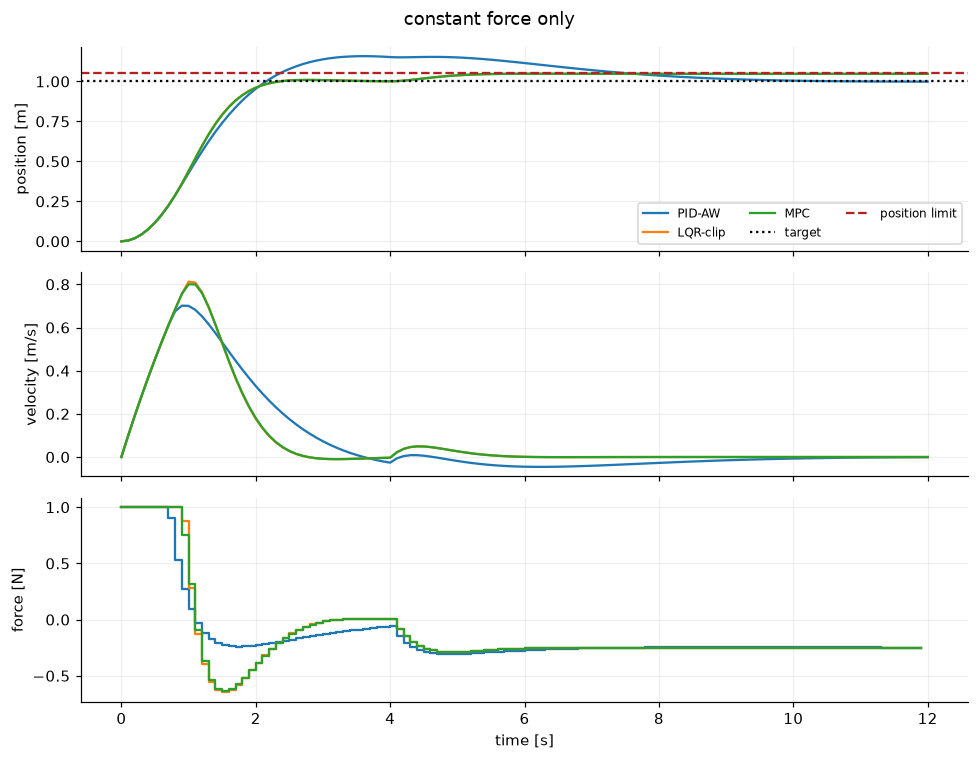


SCENARIO: heavier cart only
controller       settle_s   overshoot_m  tail_error_m        effort    stage_cost   u_violation   v_violation   p_violation
PID-AW            7.20000       0.17337       0.00070       1.41591     244.73089       0.00000       0.00000       0.12337
LQR-clip          4.40000       0.06232       0.00000       2.02154     233.65293       0.00000       0.00000       0.01232
MPC                   nan       0.04959           nan           nan           nan       0.00000       0.00000       0.00000
  STOPPED: step 26: MPC status=infeasible; no action was applied


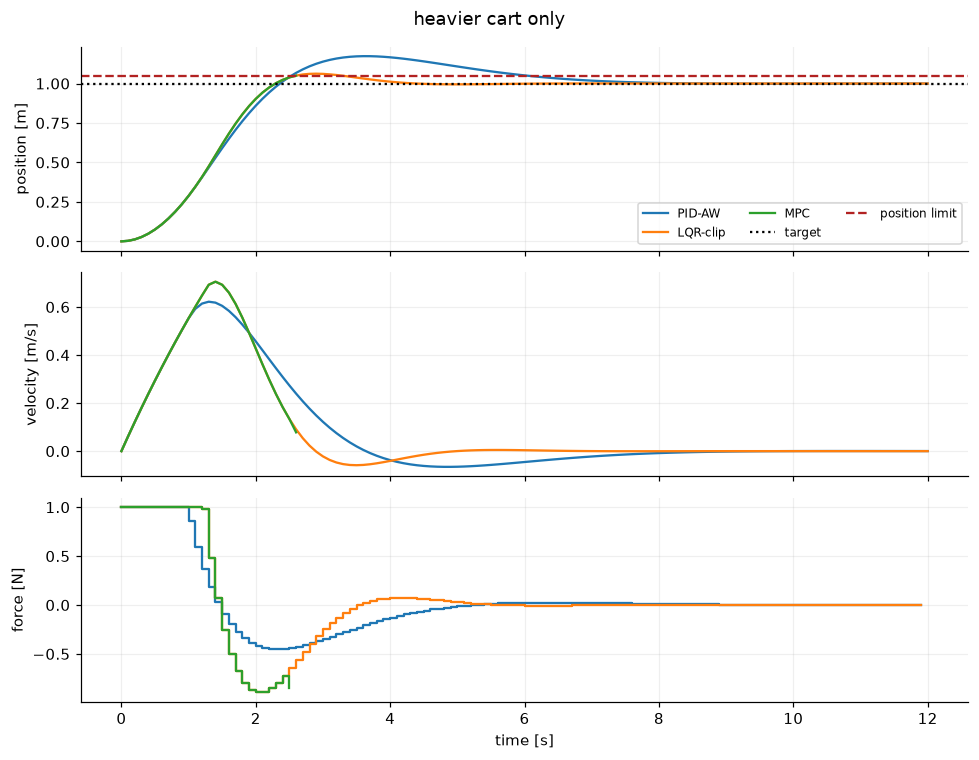


SCENARIO: heavier cart + force
controller       settle_s   overshoot_m  tail_error_m        effort    stage_cost   u_violation   v_violation   p_violation
PID-AW            8.40000       0.17337      -0.00013       1.91816     251.44499       0.00000       0.00000       0.12337
LQR-clip              nan       0.06232      -0.04755       2.50838     239.27291       0.00000       0.00000       0.01232
MPC                   nan       0.04959           nan           nan           nan       0.00000       0.00000       0.00000
  STOPPED: step 26: MPC status=infeasible; no action was applied


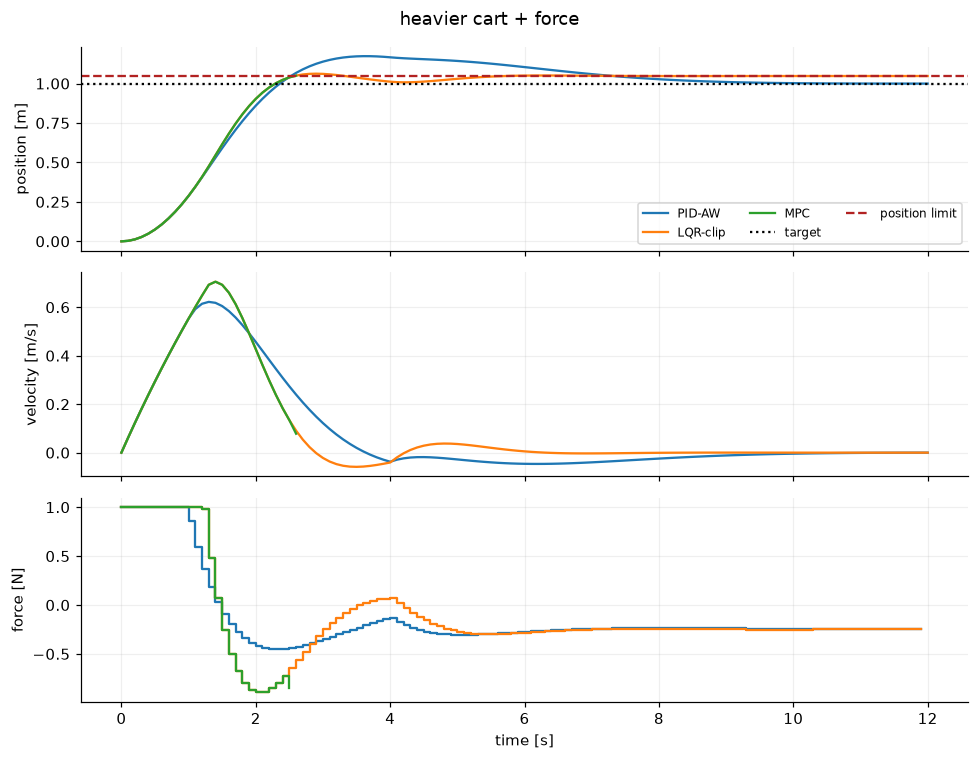

In [7]:
wind = lambda k: 0.25 if k >= 40 else 0.0
scenarios = {
    "constant force only": ((A, B), wind),
    "heavier cart only": (model(mass=1.6), None),
    "heavier cart + force": (model(mass=1.6), wind),
}
stress = {}
for scenario, (plant, disturbance) in scenarios.items():
    runs = {name: run_checked(policy, plant, disturbance)
            for name, policy in controllers().items()}
    stress[scenario] = runs
    print("\nSCENARIO:", scenario)
    show_table(runs)
    plot_runs(as_curves(runs), scenario, wall=1.05)


### 怎样写实验结论？

按输出填写“场景 → 观察 → 机制 → 下一步”。例如：

- 位置末尾有偏差 → 恒定外力下目标输入仍设为零 → 加入积分或扰动估计与稳态目标计算。
- 真实速度越界但预测满足 → 模型低估惯性或扰动 → 研究模型辨识、约束收紧或鲁棒设计。
- 某步 QP 不可行 → 检查那一步的初始状态、制动能力和约束 → 区分物理不可行与数值求解问题。

不要将“本例某组固定 PID 更好/更差”写成所有 PID 或所有 MPC 的结论。更完整的比较还应给 PID/LQR 设计参考轨迹、扫增益或权重，并展示多指标 Pareto 权衡。


## 5. 为什么每步重算：一次计划与滚动计划

给两个控制器相同的 40 步初始优化问题。开环执行初始全部输入；滚动控制每步更新状态并把 40 步视野向前延伸。第 0.8–1.5 秒施加同样的短时外力 0.2 N。

这对比的是实际“开环计划 vs 滚动闭环”，滚动方案同时拥有状态更新和延伸视野；不能把差别全部归因于其中单独一个因素。


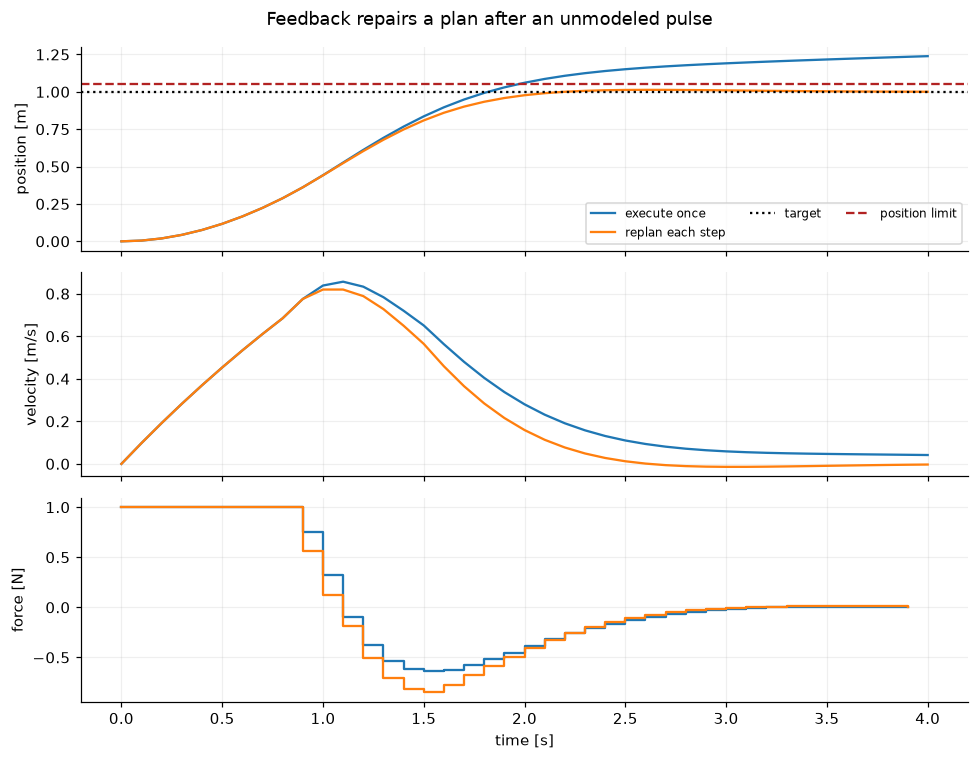

open final state: [1.2386 0.0417] failure: None
receding final state: [ 1.0007 -0.0031] failure: None


In [8]:
solver = make_mpc(horizon=40)
initial_plan = solver(np.zeros(2))
pulse = lambda k: 0.2 if 8 <= k < 15 else 0.0
open_run = run_checked(lambda x, k: float(np.clip(initial_plan["U"][k], -1, 1)),
                       disturbance=pulse, steps=40)
closed_run = run_checked(lambda x, k: solver(x)["u"], disturbance=pulse, steps=40)
plot_runs({"execute once": (open_run["xs"], open_run["us"]),
           "replan each step": (closed_run["xs"], closed_run["us"])},
          "Feedback repairs a plan after an unmodeled pulse", wall=1.05)
for name, run in {"open": open_run, "receding": closed_run}.items():
    print(name, "final state:", run["xs"][-1], "failure:", run["failure"])


## 6. 接上真实的信息条件：只有位置测量的 MPC

到现在综合实验都使用完整真状态。这里将第 03 篇 Kalman 滤波与 MPC 连接：

**测位置 → 校正当前估计 → 以估计状态优化 → 执行第一步 → 预测下一步。**

真实速度不会进入控制器。为了比较估计影响，保留一条同模型、真状态 MPC 的名义轨迹作为参考。测量噪声标准差 0.01 m，随机种子固定。

这里使用 certainty-equivalent / 确定性等价设计：把状态估计当成真实初始状态求解。即使预测约束全部满足，估计误差也可能导致实际越界。Kalman + MPC 不自动变成鲁棒 MPC，也不自动获得 LQG 无约束问题的最优性。


controller       settle_s   overshoot_m  tail_error_m        effort    stage_cost   u_violation   v_violation   p_violation
true-state        2.60000       0.00928       0.00000       1.25072     191.69483       0.00000       0.00000       0.00000
estimated             nan       0.00790      -0.00248       1.27945     191.87366       0.00000       0.00051       0.00000


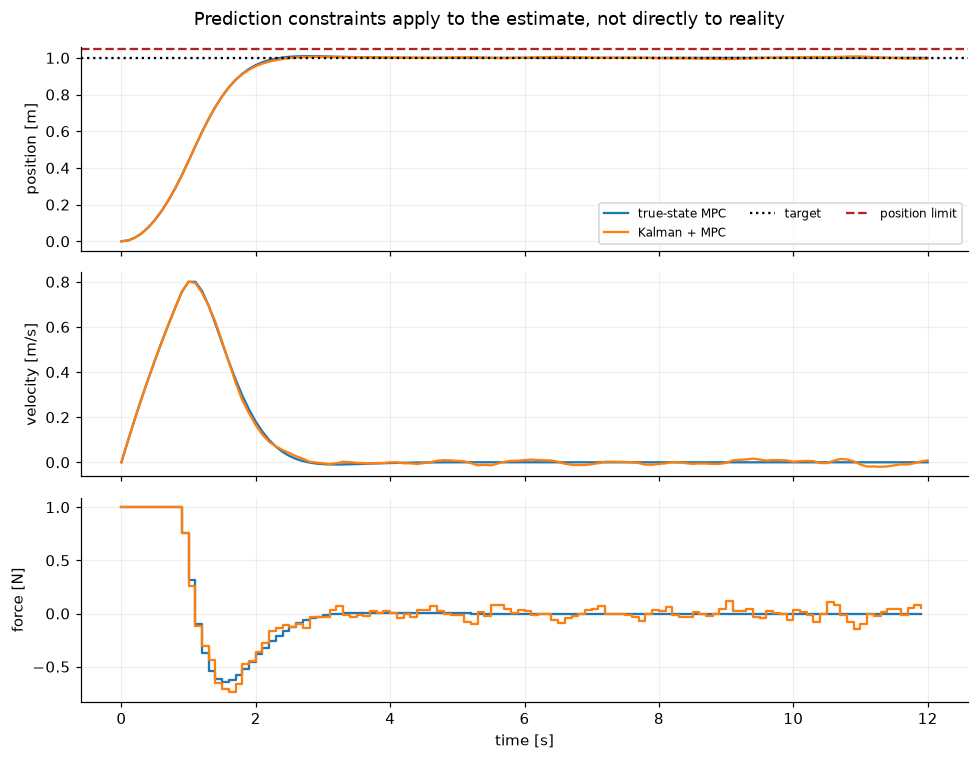

Estimation RMSE [position, velocity]: [0.0048 0.0156]


In [9]:
rng = np.random.default_rng(21)
measurement_noise = rng.normal(0, 0.01, 120)
W = np.diag([1e-7, 1e-4])
V = 0.01**2
prior, cov = np.zeros(2), np.diag([0.01, 0.2])
solver = make_mpc()
estimated_states = []

def output_mpc(x_for_sensor_only, k):
    global prior, cov
    y = x_for_sensor_only[0] + measurement_noise[k]
    innovation = y-(C@prior).item()
    gain = cov@C.T/((C@cov@C.T).item()+V)
    post = prior+gain[:, 0]*innovation
    ILC = np.eye(2)-gain@C
    postcov = ILC@cov@ILC.T+V*gain@gain.T
    result = solver(post)
    u = result["u"]
    estimated_states.append(post.copy())
    prior = A@post+b*u
    cov = A@postcov@A.T+W
    return u

output_run = run_checked(output_mpc)
show_table({"true-state": nominal["MPC"], "estimated": output_run})
plot_runs({"true-state MPC": (nominal["MPC"]["xs"], nominal["MPC"]["us"]),
           "Kalman + MPC": (output_run["xs"], output_run["us"])},
          "Prediction constraints apply to the estimate, not directly to reality", wall=1.05)
if estimated_states:
    estimated = np.asarray(estimated_states)
    true_used = output_run["xs"][:len(estimated)]
    print("Estimation RMSE [position, velocity]:",
          np.sqrt(np.mean((estimated-true_used)**2, axis=0)))


## 7. 从实验到下一代方法：每种方法补哪一个缺口？

下列是**原理路线与扩展任务**，不是本书已经实现并验证的控制器。

| 当前缺口 | 方法 | 仍研究这辆小车时改什么 |
|---|---|---|
| 常值外力导致偏差 | Offset-free MPC | 估计外力、解稳态目标，再优化偏差 |
| 有界未知外力影响约束 | 鲁棒 MPC / tube MPC | 用反馈把真实轨迹包在名义轨迹周围，收紧约束 |
| 噪声按概率描述 | 随机 MPC / 机会约束 | 把允许的越界概率明确写入约束 |
| 摩擦、推力映射非线性 | 非线性 MPC | 用非线性动力学，多次线性化或非线性规划 |
| 质量随载荷变化 | 自适应控制 / 自适应 MPC | 在线辨识质量并更新模型，同时处理辨识不确定性 |
| 模型来源于数据 | 数据驱动 / 学习增强控制 | 学习动力学或残差，验证误差界与分布外行为 |
| 每步 QP 太慢 | 显式 MPC、稀疏求解、代码生成 | 离线分区策略或优化在线计算，不改变任务本质 |

### 7.1 Tube MPC 的最小数学图景

设真实系统 $x^+=Ax+Bu+w$，$w\in\mathcal W$。名义系统 $z^+=Az+Bv$，输入采用 $u=v+K_t(x-z)$，使 $A+BK_t$ 稳定。误差 $e=x-z$ 满足：

$$e^+=(A+BK_t)e+w.$$

若能构造鲁棒正不变集 $\mathcal E$，使 $(A+BK_t)\mathcal E\oplus\mathcal W\subseteq\mathcal E$，则约束可收紧为：

$$z\in\mathcal X\ominus\mathcal E,\qquad v\in\mathcal U\ominus K_t\mathcal E.$$

$\oplus$ 是集合相加，$\ominus$ 是 Pontryagin 差：名义点加上任何允许误差后仍必须位于原约束内。这个误差管加上合适终端设计与初始条件，才构成鲁棒可行性论证；随手把边界从 1.05 改到 1.00 只是经验留余量。

### 7.2 机会约束：把“多大概率”写清楚

若预测位置近似 $p_i\sim\mathcal N(\mu_i,\sigma_i^2)$，单步约束
$\Pr(p_i\le p_{\max})\ge1-\alpha$ 可转成：

$$\mu_i+\Phi^{-1}(1-\alpha)\sigma_i\le p_{\max}.$$

每一步 99% 不等于整段轨迹 99%；联合风险需要分配或直接建模。估计误差、模型误差与未来过程噪声也都要进入预测不确定性。

### 7.3 非线性与学习不只是换求解器

若引入库仑摩擦、死区、速度相关推力，模型不再是固定 A/B；非线性 MPC 往往需要非凸优化，局部最优、初值、收敛和超时都成为实际问题。学习模型能改善预测，但控制保证依赖模型误差与部署分布，不能由训练误差直接推出。


## 8. 贯穿案例的三个研究作业

### 作业 A · 完成 offset-free MPC（建议首先做）

1. 用第三篇 $[p,v,d]$ 增广模型，验证可观性。
2. 用滤波器估计缓慢变化的外力，记录 $\hat d$。
3. 每步计算 $x_s=[r,0],u_s=-\hat d$，在动力学中加入 $B\hat d$，代价改为状态和输入相对稳态的偏差。
4. 重跑 0.25 N 阶跃外力，比较普通 MPC 与新方法的末尾位置误差及约束违反。
5. 再测试 1.2 N 外力，解释为何执行器无法维持静止，不能把“消除偏差”作为无条件要求。

**完成判据：** 名义模型、无噪声、可行外力下末尾误差趋近零；有噪声时报告重复实验的误差统计；不可行外力要检测并说明。

### 作业 B · MPC 何时值得用？

保持试验场景不变，扫描 PID 增益、LQR 的 R、MPC 的 N。画“停稳时间—控制努力—最大速度违反”而非只报告一个最优数字。

**完成判据：** 所有设计用同一测试集；明确失败轨迹；给出两组不同取舍的设计，解释为什么都可能合理。

### 作业 C · 为约束保证补上证据

构造满足局部 LQR 可行性的终端集合，或给有界扰动构造误差不变集。对状态网格检查可行域，画出“位置—速度”平面上的能停与不能停区域。

**完成判据：** 区分网格仿真证据与数学不变性论证；终端集合里的点不能仅因当前满足约束就被认定为安全。


## 9. 一页知识地图

| 你在问什么 | 先找哪个概念 | 不能混淆的另一件事 |
|---|---|---|
| 自然响应会衰减吗？ | 极点 / 特征值 / Lyapunov | 受限执行器下仍稳定吗？ |
| 输入能影响所有状态吗？ | 可控性 / 可稳定性 | 在约束下可达吗？ |
| 测量足以恢复状态吗？ | 可观性 / 可检测性 | 有噪声时估计误差多大？ |
| 怎样平衡快与省力？ | LQR 二次代价 | 权重不是硬约束 |
| 看不见的速度如何获得？ | 状态观测器 / Kalman | 估计器不会创造缺失信息 |
| 未来限制怎样一起考虑？ | MPC 有限时域优化 | 可行不等于递归可行 |
| 外力让目标偏掉怎么办？ | 积分 / 扰动增广 / 稳态目标 | 重优化不自动消除静差 |
| 模型错了还安全吗？ | 鲁棒控制 / 概率约束 | 名义约束满足不等于真实保证 |

**现在应该能完整讲述：** 从牛顿方程出发，P 反馈纠正位置，D 帮助刹车，I 补偿常值外力；状态空间把位置和速度统一组织，LQR 明确性能权衡；观测器补齐不可直接测量的状态；MPC 把未来约束写入优化，滚动重算利用新信息；鲁棒、随机、非线性与学习方法进一步处理不同来源的模型与现实差异。


## 10. 资料：按遇到的问题读，不按书的厚度读

以下链接用于继续学习；运行 Notebook 不需要访问它们。

1. **经典控制、状态空间、反馈设计：** Åström & Murray, *Feedback Systems*，[作者维护的免费教材站](https://fbswiki.org/wiki/index.php?title=Feedback_Systems:_An_Introduction_for_Scientists_and_Engineers)。配合 00–03 阅读建模、状态反馈、观测器、PID 与频域内容。
2. **MPC 的理论、终端条件、鲁棒控制与估计：** Rawlings, Mayne & Diehl, *Model Predictive Control: Theory, Computation, and Design*，[作者图书页面](https://sites.engineering.ucsb.edu/~jbraw/pubs_books.html)、[第二版 PDF](https://sites.engineering.ucsb.edu/~jbraw/mpc/MPC-book-2nd-edition-5th-printing.pdf)。先读引言与线性约束控制，再读稳定性与鲁棒章节。
3. **凸优化背景：** Boyd & Vandenberghe, *Convex Optimization*，[作者教材页](https://web.stanford.edu/~boyd/cvxbook/)。重点看凸集、二次规划、对偶与数值求解，不必为运行本例先读完整本书。
4. **离散化：** [SciPy `cont2discrete`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.cont2discrete.html)；**LQR：** [SciPy `solve_discrete_are`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve_discrete_are.html)。对应代码中的模型与 DARE。
5. **优化建模与状态检查：** [CVXPY 求解器与 warm start](https://www.cvxpy.org/tutorial/solvers/index.html)、[CVXPY 入门与不可行状态](https://www.cvxpy.org/tutorial/intro/index.html)。对应 MPC 的 Parameter、solve、status。
6. **稀疏 QP 的 MPC 实例：** [OSQP 官方 MPC 示例](https://osqp.org/docs/examples/mpc.html)。本书先用便于逐项对照公式的 CVXPY；再读此例理解直接组装稀疏矩阵。

### 最后的验收问题

不看笔记，画出闭环框图，写出一次 MPC 的目标函数与约束，并解释：

- 为什么 $p=1$ 但 $v\ne0$ 还没停好？
- 为什么 PID、LQR 和 MPC 不是三种互斥的世界观？
- 为什么只执行一项未来输入，却仍要优化整段输入？
- 为什么求解器最优、预测满足约束、真实安全是三个不同的判断？

能用本书实验回答这些问题，就已经建立了继续读现代控制教材的主干。
